In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/content/drive/MyDrive/ml-32m'
FIG_DIR = 'fig'
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'figure.figsize': (3.25, 2.4), 'font.size': 8, 'axes.titlesize': 8,
                     'axes.labelsize': 8, 'legend.fontsize': 7, 'savefig.bbox': 'tight'})

def save(name):
  plt.savefig(os.path.join(FIG_DIR, name + '.pdf'))
  plt.show()

In [3]:
ratings_df = pd.read_csv(os.path.join(DATA_DIR, 'ratings.csv'),
                         dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'})
movies_df = pd.read_csv(os.path.join(DATA_DIR, 'movies.csv'))
ratings_df['date'] = pd.to_datetime(ratings_df['timestamp'], unit='s')
print(ratings_df.shape)
print(ratings_df.head())

(32000204, 5)
   userId  movieId  rating  timestamp                date
0       1       17     4.0  944249077 1999-12-03 19:24:37
1       1       25     1.0  944250228 1999-12-03 19:43:48
2       1       29     2.0  943230976 1999-11-22 00:36:16
3       1       30     5.0  944249077 1999-12-03 19:24:37
4       1       32     5.0  943228858 1999-11-22 00:00:58


## Size and sparsity

In [4]:
n_ratings = len(ratings_df)
n_users = ratings_df['userId'].nunique()
n_items = ratings_df['movieId'].nunique()
n_movies_listed = len(movies_df)
density = n_ratings / (n_users * n_items)

print(f'ratings:            {n_ratings:,}')
print(f'users:              {n_users:,}')
print(f'movies with ratings:{n_items:,}  (movies.csv lists {n_movies_listed:,})')
print(f'matrix cells:       {n_users * n_items:,}')
print(f'density:            {100 * density:.3f} %   -> {100 * (1 - density):.2f} % of the matrix is empty')
print(f'first rating:       {ratings_df["date"].min().date()}')
print(f'last rating:        {ratings_df["date"].max().date()}')

ratings:            32,000,204
users:              200,948
movies with ratings:84,432  (movies.csv lists 87,585)
matrix cells:       16,966,441,536
density:            0.189 %   -> 99.81 % of the matrix is empty
first rating:       1995-01-09
last rating:        2023-10-13


## Distribution of the ratings

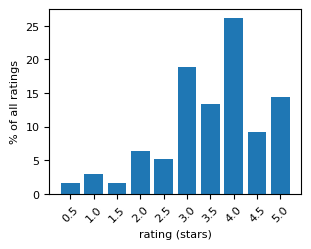

mean rating 3.540, std 1.086
whole-star ratings: 68.7 %   (half stars are used less)
most common rating: 4.0


In [5]:
counts = ratings_df['rating'].value_counts().sort_index()
mean_rating = ratings_df['rating'].mean()
std_rating = ratings_df['rating'].std()

plt.figure()
plt.bar(counts.index, counts.values / n_ratings * 100, width=0.4)
plt.xlabel('rating (stars)'); plt.ylabel('% of all ratings')
plt.xticks(np.arange(0.5, 5.5, 0.5), rotation=45)
save('rating_hist')

whole = counts[counts.index == counts.index.round()].sum() / n_ratings
print(f'mean rating {mean_rating:.3f}, std {std_rating:.3f}')
print(f'whole-star ratings: {100 * whole:.1f} %   (half stars are used less)')
print(f'most common rating: {counts.idxmax()}')

## Ratings per user and per movie (power laws)

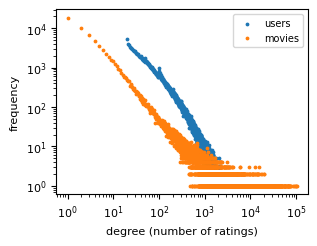

users   min     20  median     73  mean    159.2  max   33332
movies  min      1  median      5  mean    379.0  max  102929


In [6]:
user_degree = ratings_df.groupby('userId').size()
item_degree = ratings_df.groupby('movieId').size()

def degree_plot(deg, label):
  freq = deg.value_counts().sort_index()          # how many users/movies have degree d
  plt.scatter(freq.index, freq.values, s=3, label=label)

plt.figure()
degree_plot(user_degree, 'users')
degree_plot(item_degree, 'movies')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('degree (number of ratings)'); plt.ylabel('frequency')
plt.legend()
save('degrees')

for name, deg in [('users', user_degree), ('movies', item_degree)]:
  print(f'{name:7s} min {deg.min():6d}  median {int(deg.median()):6d}  mean {deg.mean():8.1f}  max {deg.max():7d}')

## The long tail

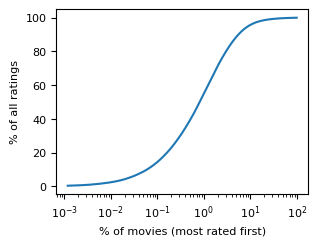

top    1 % of movies receive 54.8 % of the ratings
top    5 % of movies receive 88.6 % of the ratings
top   10 % of movies receive 95.7 % of the ratings
top   20 % of movies receive 98.6 % of the ratings
movies with < 10 ratings:  62.1 %
movies with < 100 ratings: 85.6 %   (we filter these out when recommending)


In [7]:
sorted_items = np.sort(item_degree.values)[::-1]           # most rated first
cum_share = np.cumsum(sorted_items) / sorted_items.sum()
movie_share = np.arange(1, len(sorted_items) + 1) / len(sorted_items)

plt.figure()
plt.plot(movie_share * 100, cum_share * 100)
plt.xlabel('% of movies (most rated first)'); plt.ylabel('% of all ratings')
plt.xscale('log')
save('long_tail')

for p in [0.01, 0.05, 0.10, 0.20]:
  k = int(p * len(sorted_items))
  print(f'top {100*p:4.0f} % of movies receive {100 * cum_share[k - 1]:.1f} % of the ratings')
rare = (item_degree < 100).mean()
few = (item_degree < 10).mean()
print(f'movies with < 10 ratings:  {100 * few:.1f} %')
print(f'movies with < 100 ratings: {100 * rare:.1f} %   (we filter these out when recommending)')

## Users and movies are different on average

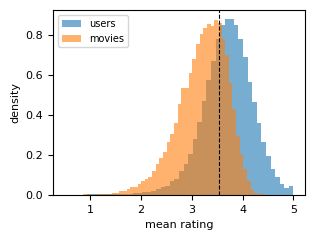

std of user means  (>=20 ratings): 0.487
std of movie means (>=20 ratings): 0.476


In [8]:
user_mean = ratings_df.groupby('userId')['rating'].mean()
item_mean = ratings_df.groupby('movieId')['rating'].mean()

plt.figure()
plt.hist(user_mean[user_degree >= 20], bins=50, alpha=0.6, density=True, label='users')
plt.hist(item_mean[item_degree >= 20], bins=50, alpha=0.6, density=True, label='movies')
plt.axvline(mean_rating, color='k', lw=0.8, ls='--')
plt.xlabel('mean rating'); plt.ylabel('density'); plt.legend()
save('mean_ratings')

print(f'std of user means  (>=20 ratings): {user_mean[user_degree >= 20].std():.3f}')
print(f'std of movie means (>=20 ratings): {item_mean[item_degree >= 20].std():.3f}')

## Do popular movies get higher ratings?

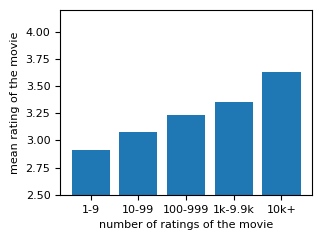

         movies  mean rating
1-9       52471        2.910
10-99     19770        3.079
100-999    7794        3.238
1k-9.9k    3625        3.351
10k+        772        3.625


In [9]:
bins = [1, 10, 100, 1000, 10000, 10**6]
labels = ['1-9', '10-99', '100-999', '1k-9.9k', '10k+']
group = pd.cut(item_degree, bins=bins, right=False, labels=labels)
by_pop = item_mean.groupby(group, observed=False).mean()
n_by_pop = item_mean.groupby(group, observed=False).size()

plt.figure()
plt.bar(by_pop.index.astype(str), by_pop.values)
plt.ylim(2.5, 4.2)
plt.xlabel('number of ratings of the movie'); plt.ylabel('mean rating of the movie')
save('popularity_vs_rating')
print(pd.DataFrame({'movies': n_by_pop, 'mean rating': by_pop.round(3)}))

## Time

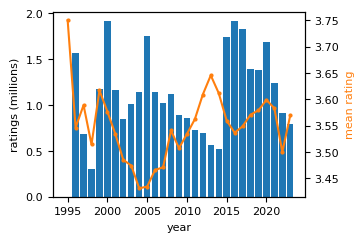

users active on a single day: 58.8 %
median activity span: 0 days


In [10]:
per_year = ratings_df.groupby(ratings_df['date'].dt.year).size()
mean_per_year = ratings_df.groupby(ratings_df['date'].dt.year)['rating'].mean()

fig, ax1 = plt.subplots()
ax1.bar(per_year.index, per_year.values / 1e6, color='C0')
ax1.set_xlabel('year'); ax1.set_ylabel('ratings (millions)')
ax2 = ax1.twinx()
ax2.plot(mean_per_year.index, mean_per_year.values, color='C1', marker='o', ms=2)
ax2.set_ylabel('mean rating', color='C1')
save('ratings_per_year')

# How long is a user active? (days between first and last rating)
first_last = ratings_df.groupby('userId')['timestamp'].agg(['min', 'max'])
span_days = (first_last['max'] - first_last['min']) / 86400
print(f'users active on a single day: {100 * (span_days < 1).mean():.1f} %')
print(f'median activity span: {span_days.median():.0f} days')

## Genres

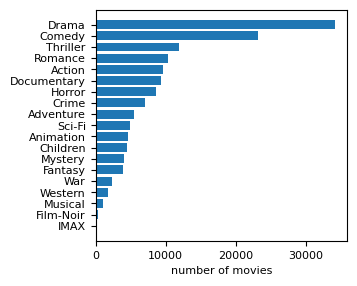

In [11]:
genres = movies_df['genres'].str.split('|').explode()
genre_counts = genres.value_counts()
genre_counts = genre_counts[genre_counts.index != '(no genres listed)']

plt.figure(figsize=(3.25, 3.0))
plt.barh(genre_counts.index[::-1], genre_counts.values[::-1])
plt.xlabel('number of movies')
save('genres')

## The split by time, and a trivial baseline

In [12]:
ratings_df = ratings_df.sort_values(['userId', 'timestamp'])
position = ratings_df.groupby('userId').cumcount()                     # 0, 1, 2, ... in time order
n_user = ratings_df.groupby('userId')['rating'].transform('size')
n_test = (n_user * 0.1).astype(int)
is_test = position >= (n_user - n_test)

train_df, test_df = ratings_df[~is_test], ratings_df[is_test]
print(f'train {len(train_df):,}   test {len(test_df):,}   ({100 * len(test_df) / n_ratings:.1f} %)')
print(f'test ratings per user: min {n_test.groupby(ratings_df["userId"]).first().min()}')

# Movies in the test set that never appear in train (cold-start movies)
new_items = ~test_df['movieId'].isin(train_df['movieId'].unique())
print(f'test ratings on movies never seen in train: {100 * new_items.mean():.2f} %')

def rmse(pred, r):
  return np.sqrt(np.mean((r - pred) ** 2))

mu = train_df['rating'].mean()
base_global = rmse(mu, test_df['rating'].values)

u_mean = train_df.groupby('userId')['rating'].mean()
base_user = rmse(test_df['userId'].map(u_mean).fillna(mu).values, test_df['rating'].values)

i_mean = train_df.groupby('movieId')['rating'].mean()
base_item = rmse(test_df['movieId'].map(i_mean).fillna(mu).values, test_df['rating'].values)

print(f'test RMSE, global mean:     {base_global:.4f}')
print(f'test RMSE, user mean:       {base_user:.4f}')
print(f'test RMSE, movie mean:      {base_item:.4f}')

train 28,885,713   test 3,114,491   (9.7 %)
test ratings per user: min 2
test ratings on movies never seen in train: 0.28 %
test RMSE, global mean:     1.0578
test RMSE, user mean:       0.9589
test RMSE, movie mean:      0.9638
